In [24]:
import os
import torch
import torchvision
import pandas as pd

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

image_dir = "fifa/Images"
data = pd.read_csv("fifa/data.csv")

# Conservar únicamente imágenes que Pillow pueda abrir
valid_paths = []

for filename in os.listdir(image_dir):
    path = os.path.join(image_dir, filename)

    if not filename.lower().endswith((".png", ".jpg", ".jpeg", ".webp")):
        continue

    try:
        with Image.open(path) as img:
            img.verify()
        valid_paths.append(path)
    except Exception:
        continue

# Orden numérico, como en el código original
valid_paths.sort(
    key=lambda p: int(os.path.splitext(os.path.basename(p))[0])
)

print("Imágenes válidas:", len(valid_paths))


class FIFADataset(Dataset):
    def __init__(self, paths):
        self.paths = paths
        self.transform = transforms.Compose([
            transforms.Resize(
                (128, 128),
                interpolation=transforms.InterpolationMode.LANCZOS
            ),
            transforms.ToTensor(),
            transforms.Normalize((0.5, 0.5, 0.5),
                                (0.5, 0.5, 0.5))
        ])

    def __len__(self):
            return len(self.paths)

    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as im:
            rgba = im.convert("RGBA")

        # Componer sobre negro usando transparencia real
        background = Image.new("RGBA", rgba.size, (0, 0, 0, 255))
        rgb = Image.alpha_composite(background, rgba).convert("RGB")

        return self.transform(rgb)

dataset = FIFADataset(valid_paths)
print("Cantidad de imágenes:", len(dataset))
print("Forma:", dataset[0].shape)
sample = dataset[0]
print("Rango de una imagen:", sample.min().item(), sample.max().item())

Imágenes válidas: 15234
Cantidad de imágenes: 15234
Forma: torch.Size([3, 128, 128])
Rango de una imagen: -1.0 1.0


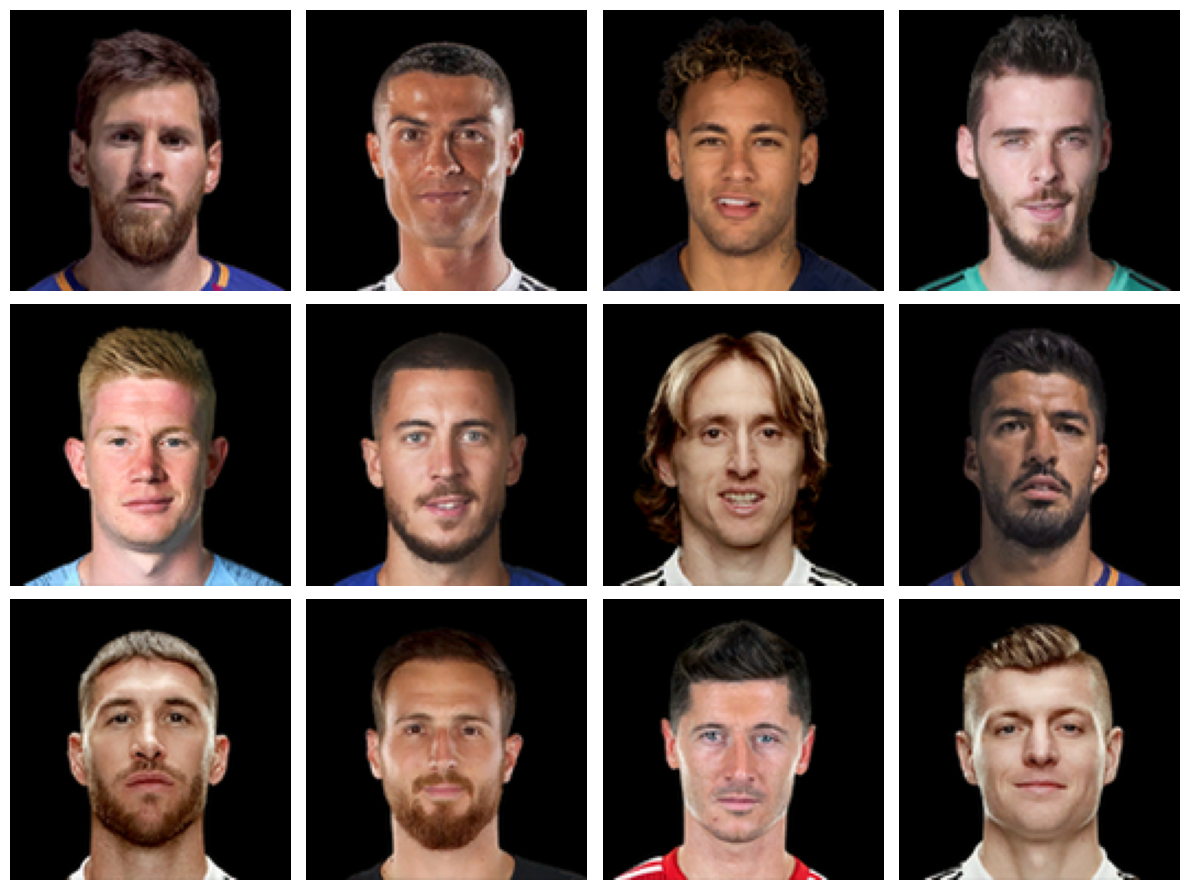

In [46]:
import matplotlib.pyplot as plt
import random

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for ax, idx in zip(
    axes.flat,
    #random.sample(range(len(dataset)), 12)
    range(12)
):
    img = dataset[idx]
    img = (img * 0.5 + 0.5).clamp(0, 1)

    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.axis("off")

plt.tight_layout()
plt.show()

In [26]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

latent_dim = 100
channels_img = 3
features_g = 64
features_d = 64
batch_size = 32

lr = 0.0002
beta1 = 0.5
beta2 = 0.999

print(device)

cuda


In [ ]:
class Generator(nn.Module):
    def __init__(self, latent_dim=100, channels_img=3, features_g=64):
        super().__init__()

        self.net = nn.Sequential(
            # 1x1 -> 4x4
            nn.ConvTranspose2d(latent_dim, features_g * 16, 4, 1, 0, bias=False),
            nn.BatchNorm2d(features_g * 16),
            nn.ReLU(True),

            # 4x4 -> 8x8
            nn.ConvTranspose2d(features_g * 16, features_g * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features_g * 8),
            nn.ReLU(True),

            # 8x8 -> 16x16
            nn.ConvTranspose2d(features_g * 8, features_g * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features_g * 4),
            nn.ReLU(True),

            # 16x16 -> 32x32
            nn.ConvTranspose2d(features_g * 4, features_g * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features_g * 2),
            nn.ReLU(True),

            # 32x32 -> 64x64
            nn.ConvTranspose2d(features_g * 2, features_g, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features_g),
            nn.ReLU(True),

            # 64x64 -> 128x128
            nn.ConvTranspose2d(features_g, channels_img, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z)


In [28]:
G = Generator(latent_dim, channels_img, features_g).to(device)

z = torch.randn(16, latent_dim, 1, 1, device=device)
fake = G(z)

print(fake.shape)
print(device)

torch.Size([16, 3, 128, 128])
cuda


## 6. DataLoader

Usamos `drop_last=True` para mantener lotes completos, útil para BatchNorm. En Colab, si aparece un problema con los workers, cambiá `num_workers` a `0`.


In [29]:
from torch.utils.data import DataLoader

batch_size = 32
num_workers = 2 if os.name != "nt" else 0

dataloader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
    drop_last=True,
)

print("Lotes por época:", len(dataloader))
print("Tamaño de lote:", next(iter(dataloader)).shape)


Lotes por época: 476
Tamaño de lote: torch.Size([32, 3, 128, 128])


## 7. Discriminador DCGAN

Devuelve logits, sin `Sigmoid`, porque entrenaremos con `BCEWithLogitsLoss`, que es más estable numéricamente.


In [ ]:
class Discriminator(nn.Module):
    def __init__(self, channels_img=3, features_d=64):
        super().__init__()

        self.net = nn.Sequential(
            # 128x128 -> 64x64
            nn.Conv2d(channels_img, features_d, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            # 64x64 -> 32x32
            nn.Conv2d(features_d, features_d * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features_d * 2),
            nn.LeakyReLU(0.2, inplace=True),

            # 32x32 -> 16x16
            nn.Conv2d(features_d * 2, features_d * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features_d * 4),
            nn.LeakyReLU(0.2, inplace=True),

            # 16x16 -> 8x8
            nn.Conv2d(features_d * 4, features_d * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features_d * 8),
            nn.LeakyReLU(0.2, inplace=True),

            # 8x8 -> 4x4
            nn.Conv2d(features_d * 8, features_d * 16, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features_d * 16),
            nn.LeakyReLU(0.2, inplace=True),

            # 4x4 -> 1x1
            nn.Conv2d(features_d * 16, 1, 4, 1, 0, bias=False),

            nn.Conv2d()
        )

    def forward(self, x):
        return self.net(x).view(-1)


## 8. Inicialización y comprobaciones de dimensiones

La inicialización DCGAN clásica usa pesos normales con media 0 y desviación 0.02. En BatchNorm, pesos cercanos a 1 y sesgo 0.


In [31]:
def weights_init(module):
    name = module.__class__.__name__
    if "Conv" in name:
        nn.init.normal_(module.weight.data, 0.0, 0.02)
    elif "BatchNorm" in name:
        nn.init.normal_(module.weight.data, 1.0, 0.02)
        nn.init.constant_(module.bias.data, 0)

G = Generator(latent_dim, channels_img, features_g).to(device)
D = Discriminator(channels_img, features_d).to(device)
G.apply(weights_init)
D.apply(weights_init)

# Prueba de dimensiones y valores finitos
with torch.no_grad():
    z_test = torch.randn(4, latent_dim, 1, 1, device=device)
    fake_test = G(z_test)
    logits_test = D(fake_test)

assert fake_test.shape == (4, 3, 128, 128), f"Salida G inesperada: {fake_test.shape}"
assert logits_test.shape == (4,), f"Salida D inesperada: {logits_test.shape}"
assert torch.isfinite(fake_test).all(), "G produjo NaN/Inf"
assert torch.isfinite(logits_test).all(), "D produjo NaN/Inf"

print("G:", tuple(fake_test.shape), "| D:", tuple(logits_test.shape))
print("Rango de G:", fake_test.min().item(), fake_test.max().item())


G: (4, 3, 128, 128) | D: (4,)
Rango de G: -0.8166223764419556 0.8053019046783447


## 9. Optimizadores y funciones de pérdida

Configuración DCGAN inicial: Adam con `lr=0.0002`, `betas=(0.5, 0.999)`. No es una garantía contra el colapso; es un punto de partida clásico.


In [32]:
lr = 0.00021
beta1, beta2 = 0.5, 0.999

criterion = nn.BCEWithLogitsLoss()
optimizer_G = torch.optim.Adam(G.parameters(), lr=lr, betas=(beta1, beta2))
optimizer_D = torch.optim.Adam(D.parameters(), lr=0.00005, betas=(beta1, beta2))

# Ruido fijo: las mismas 16 entradas en cada época para comparar evolución.
fixed_noise = torch.randn(16, latent_dim, 1, 1, device=device)

os.makedirs("dcgan_samples", exist_ok=True)
os.makedirs("dcgan_checkpoints", exist_ok=True)

history = {
    "D": [], "G": [], "D_real": [], "D_fake": [],
    "diversity": [], "pixel_std": []
}


## 10. Muestras y métricas de diversidad

La distancia se normaliza por la cantidad de píxeles/canales, así puede interpretarse como diferencia RMS por elemento. También medimos la desviación estándar media entre imágenes: cerca de cero significa que la salida cambia muy poco entre distintos ruidos.

Los umbrales son alertas heurísticas, no una prueba matemática de colapso.


In [33]:
from itertools import combinations

@torch.no_grad()
def sample_and_measure(noise=fixed_noise):
    G.eval()
    samples = G(noise).detach().float()
    flat = samples.flatten(1)

    # Distancia RMS promedio entre pares de imágenes
    distances = torch.pdist(flat, p=2) / (flat.shape[1] ** 0.5)
    diversity = distances.mean().item() if distances.numel() else 0.0

    # Variación media por píxel entre imágenes del lote
    pixel_std = samples.std(dim=0, unbiased=False).mean().item()

    return samples, diversity, pixel_std


def save_samples(epoch):
    samples, diversity, pixel_std = sample_and_measure()
    display = (samples[:16].cpu() * 0.5 + 0.5).clamp(0, 1)

    fig, axes = plt.subplots(4, 4, figsize=(8, 8))
    for ax, img in zip(axes.flat, display):
        ax.imshow(img.permute(1, 2, 0).numpy())
        ax.axis("off")
    plt.suptitle(
        f"Época {epoch} | diversidad={diversity:.4f} | std={pixel_std:.4f}"
    )
    plt.tight_layout()
    plt.savefig(f"dcgan_samples/epoch_{epoch:03d}.png", dpi=120)
    plt.show()
    plt.close(fig)

    return diversity, pixel_std


In [36]:
checkpoint_path = "dcgan_checkpoints/epoch_145.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

G.load_state_dict(checkpoint["G"])
D.load_state_dict(checkpoint["D"])

optimizer_G.load_state_dict(checkpoint["optimizer_G"])
optimizer_D.load_state_dict(checkpoint["optimizer_D"])

# LR inicial para esta nueva etapa.
# Se asigna DESPUÉS de cargar los optimizadores porque el checkpoint restaura sus LR.
for group in optimizer_G.param_groups:
    group["lr"] = 0.00021

for group in optimizer_D.param_groups:
    group["lr"] = 0.00005

start_epoch = checkpoint["epoch"] + 1

history = checkpoint["history"]
best_diversity = checkpoint["best_diversity"]
max(history["diversity"], default=0.0)

print(f"Checkpoint cargado: {checkpoint_path}")
print(f"Continuamos desde la época {start_epoch}")
print(f"Mejor diversidad registrada: {best_diversity:.4f}")
print(f"LR_G inicial: {optimizer_G.param_groups[0]['lr']}")
print(f"LR_D inicial: {optimizer_D.param_groups[0]['lr']}")

        # "epoch": epoch,
        # "G": G.state_dict(),
        # "D": D.state_dict(),
        # "optimizer_G": optimizer_G.state_dict(),
        # "optimizer_D": optimizer_D.state_dict(),
        # "history": history,
        # "best_diversity": best_diversity,

Checkpoint cargado: dcgan_checkpoints/epoch_145.pth
Continuamos desde la época 146
Mejor diversidad registrada: 0.4294
LR_G inicial: 0.00021
LR_D inicial: 5e-05


## 11. Entrenamiento con controles

En cada época:
- Verifica que las pérdidas sean finitas.
- Verifica que los gradientes y parámetros no contengan NaN/Inf.
- Registra pérdidas y diversidad.
- Emite una alerta si la diversidad cae drásticamente respecto de su mejor valor reciente.
- Guarda un checkpoint por época.

**Importante:** las alertas no detienen automáticamente el entrenamiento. Mirá también las imágenes guardadas; una métrica sola no detecta todos los tipos de colapso.


In [ ]:
from tqdm.auto import tqdm
import math

epochs = 80
collapse_streak = 0
best_diversity = None
bad_diversity_epochs = 0
dominance_streak = 0
weakness_streak = 0

def assert_finite_gradients(model, model_name):
    for name, p in model.named_parameters():
        if p.grad is not None and not torch.isfinite(p.grad).all():
            raise RuntimeError(f"Gradiente NaN/Inf en {model_name}.{name}")

def assert_finite_parameters(model, model_name):
    for name, p in model.named_parameters():
        if not torch.isfinite(p).all():
            raise RuntimeError(f"Parámetro NaN/Inf en {model_name}.{name}")

for epoch in range(start_epoch, 201):
# for epoch in range(1, epochs + 1):
    G.train()
    D.train()

    total_G = total_D = total_D_real = total_D_fake = 0.0

    progress = tqdm(dataloader, desc=f"Época {epoch}/{epochs+start_epoch}")
    for real in progress:
        real = real.to(device, non_blocking=True)
        batch = real.size(0)

        # --- Entrenar D ---
        optimizer_D.zero_grad(set_to_none=True)

        noise = torch.randn(batch, latent_dim, 1, 1, device=device)
        with torch.no_grad():
            fake = G(noise)

        real_logits = D(real)
        fake_logits = D(fake)

        # Suavizado leve de etiquetas reales para evitar confianza excesiva.
        real_targets = torch.full_like(real_logits, 0.9)
        fake_targets = torch.zeros_like(fake_logits)

        loss_D_real = criterion(real_logits, real_targets)
        loss_D_fake = criterion(fake_logits, fake_targets)
        loss_D = loss_D_real + loss_D_fake

        if not torch.isfinite(loss_D):
            raise RuntimeError(f"Loss D no finita en época {epoch}")

        loss_D.backward()
        assert_finite_gradients(D, "D")
        optimizer_D.step()
        assert_finite_parameters(D, "D")

        # --- Entrenar G ---
        optimizer_G.zero_grad(set_to_none=True)
        noise = torch.randn(batch, latent_dim, 1, 1, device=device)
        fake = G(noise)
        fake_logits_for_G = D(fake)

        # G intenta que D clasifique sus imágenes como reales.
        loss_G = criterion(fake_logits_for_G, torch.ones_like(fake_logits_for_G))

        if not torch.isfinite(loss_G):
            raise RuntimeError(f"Loss G no finita en época {epoch}")

        loss_G.backward()
        assert_finite_gradients(G, "G")
        optimizer_G.step()
        assert_finite_parameters(G, "G")

        total_D += loss_D.item()
        total_G += loss_G.item()
        total_D_real += torch.sigmoid(real_logits.detach()).mean().item()
        total_D_fake += torch.sigmoid(fake_logits.detach()).mean().item()

        progress.set_postfix(D=f"{loss_D.item():.3f}", G=f"{loss_G.item():.3f}")

    n = len(dataloader)
    avg_D = total_D / n
    avg_G = total_G / n
    avg_D_real = total_D_real / n
    avg_D_fake = total_D_fake / n

    # Ajuste adaptativo del LR de D si domina o se debilita durante varias épocas.
    gap = avg_D_real - avg_D_fake
    lr_D = optimizer_D.param_groups[0]["lr"]

    diversity, pixel_std = save_samples(epoch)

    history["D"].append(avg_D)
    history["G"].append(avg_G)
    history["D_real"].append(avg_D_real)
    history["D_fake"].append(avg_D_fake)
    history["diversity"].append(diversity)
    history["pixel_std"].append(pixel_std)

    # Alertas heurísticas: compara contra la mejor diversidad observada.
    if best_diversity is None:
        best_diversity = diversity
    else:
        if diversity < 0.50 * best_diversity:
            bad_diversity_epochs += 1
        else:
            bad_diversity_epochs = 0
        best_diversity = max(best_diversity, diversity)

    alerts = []
    if pixel_std < 0.03:
        alerts.append("salidas casi uniformes (pixel_std < 0.03)")
    if bad_diversity_epochs >= 2:
        alerts.append("diversidad < 50% del máximo durante 2 épocas seguidas")

    print(
        f"Época {epoch}: D={avg_D:.4f} | G={avg_G:.4f} | "
        f"D(real)={avg_D_real:.3f} | D(fake)={avg_D_fake:.3f} | "
        f"diversidad={diversity:.4f} | pixel_std={pixel_std:.4f}"
    )
    if alerts:
        print("⚠️ ALERTA DE POSIBLE COLAPSO:", "; ".join(alerts))
        print("Revisá las muestras. Si el colapso es visual, frená y volvé a un checkpoint anterior.")

    # Checkpoint completo para reanudar entrenamiento.
    torch.save({
        "epoch": epoch,
        "G": G.state_dict(),
        "D": D.state_dict(),
        "optimizer_G": optimizer_G.state_dict(),
        "optimizer_D": optimizer_D.state_dict(),
        "history": history,
        "best_diversity": best_diversity,
    }, f"dcgan_checkpoints/epoch_{epoch:03d}.pth")


## 12. Gráficos de seguimiento

La pérdida de GAN no tiene que bajar de forma monótona. Interpretala junto con muestras, probabilidades del discriminador y diversidad.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history["D"], label="Discriminador")
axes[0].plot(history["G"], label="Generador")
axes[0].set_title("Pérdidas")
axes[0].set_xlabel("Época")
axes[0].legend()

axes[1].plot(history["D_real"], label="D(real)")
axes[1].plot(history["D_fake"], label="D(fake)")
axes[1].set_title("Probabilidad media de D")
axes[1].set_xlabel("Época")
axes[1].legend()

axes[2].plot(history["diversity"], label="Distancia RMS")
axes[2].plot(history["pixel_std"], label="Std por píxel")
axes[2].set_title("Diversidad")
axes[2].set_xlabel("Época")
axes[2].legend()

plt.tight_layout()
plt.show()

print("Discriminator: ", history["D"])
print("Generador: ", history["G"])
print("D(real): ", history["D_real"])
print("D(fake): ", history["D_fake"])
print("Best Diversity: ",best_diversity)
